# Medium sample

This notebook looks at `medium-sampled-2026-10-14.zip`. The posts run from January 2020 through 17 September 2026. We use December 2022 as the break, the first full month after ChatGPT went public.

Sampling finished for all 81 months. The zip still says the analytic check is open, so this is a look at the sample. The two shard files in the same folder are the raw crawl. We leave them out.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# csv extracts pulled from the sampled zip
candidates = [
    Path("data/medium_eda"),
    Path("../data/medium_eda"),
    Path("/Users/kofibadu/Desktop/cap folder/data/medium_eda"),
]
DATA = next(p for p in candidates if (p / "monthly_coverage.csv").exists())

coverage = pd.read_csv(DATA / "monthly_coverage.csv")
volume = pd.read_csv(DATA / "creator_month_volume.csv", parse_dates=["year_month"])
repeat = pd.read_csv(DATA / "creator_repeat.csv")
posts = pd.read_csv(DATA / "post_length.csv", parse_dates=["year_month"])
CUT = pd.Timestamp("2022-12-01")

print("coverage rows", f"{len(coverage):,}", "  months", coverage["year_month"].nunique())
print("creator-months kept", f"{int(volume['sampled_creators'].sum()):,}")
print("posts kept", f"{int(volume['selected_posts'].sum()):,}")
print("creators", f"{int(repeat['creators'].sum()):,}")


coverage rows 648   months 81
creator-months kept 201,520
posts kept 294,671
creators 105,675


## Who got in

We keep up to 2,500 creators a month. To get in, a creator needs an English post of at least 200 words. January and February 2020 come in under the cap. July 2022 is the other short month, at 2,479.


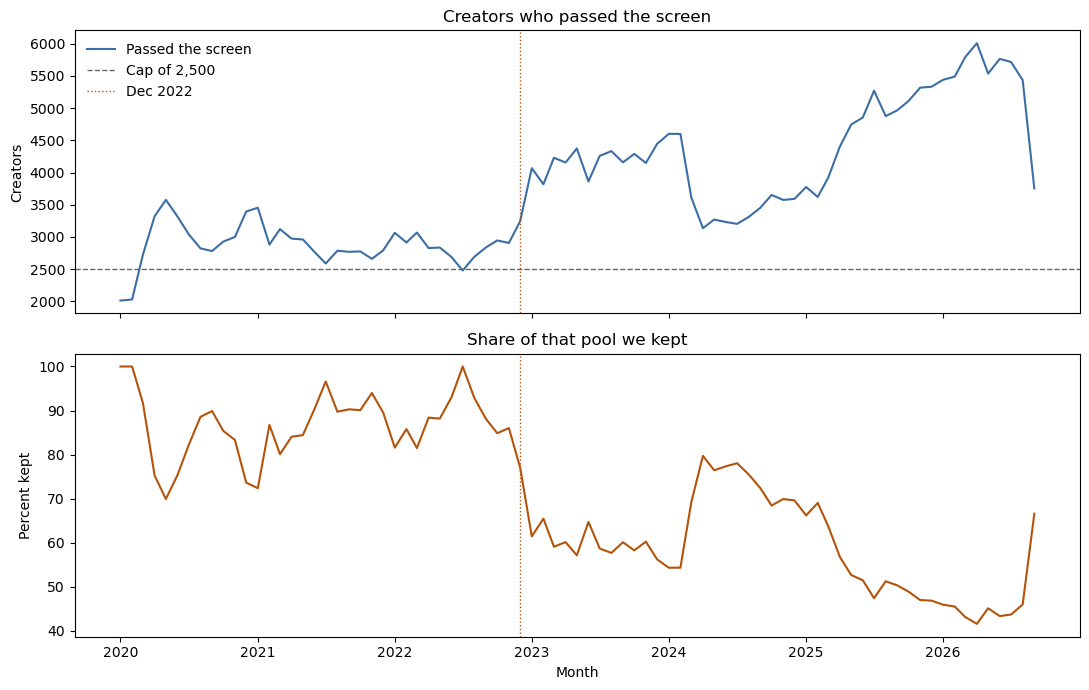

,year_month,eligible,sampled,kept_pct
0,2020-01,2012,2012,100.000000
34,2022-11,2906,2500,86.028906
35,2022-12,3245,2500,77.041602
79,2026-08,5436,2500,45.989698
80,2026-09,3754,2500,66.595631


In [2]:
month = (
    coverage.groupby("year_month", as_index=False)
    .agg(eligible=("screened_candidate_creators", "sum"), sampled=("sampled_creators", "sum"))
)
month["year_month"] = pd.to_datetime(month["year_month"] + "-01")
month["kept_pct"] = 100 * month["sampled"] / month["eligible"]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(month["year_month"], month["eligible"], color="#3b6ea5", label="Passed the screen")
axes[0].axhline(2500, color="#666666", ls="--", lw=1, label="Cap of 2,500")
axes[0].axvline(CUT, color="#b45309", ls=":", lw=1, label="Dec 2022")
axes[0].set_ylabel("Creators")
axes[0].set_title("Creators who passed the screen")
axes[0].legend(frameon=False, loc="upper left")
axes[1].plot(month["year_month"], month["kept_pct"], color="#b45309")
axes[1].axvline(CUT, color="#b45309", ls=":", lw=1)
axes[1].set_ylabel("Percent kept")
axes[1].set_xlabel("Month")
axes[1].set_title("Share of that pool we kept")
fig.tight_layout()
plt.show()

checkpoints = pd.to_datetime(["2020-01-01", "2022-11-01", "2022-12-01", "2026-08-01", "2026-09-01"])
picked = month[month["year_month"].isin(checkpoints)].copy()
picked["year_month"] = picked["year_month"].dt.strftime("%Y-%m")
picked


## Posts we kept

A creator can contribute 1, 2, or 3 posts. The files also count every post from that creator-month that passed the screen, so the qualifying count can be higher. In every month the typical creator has 1 qualifying post, so the cap of 3 rarely matters.


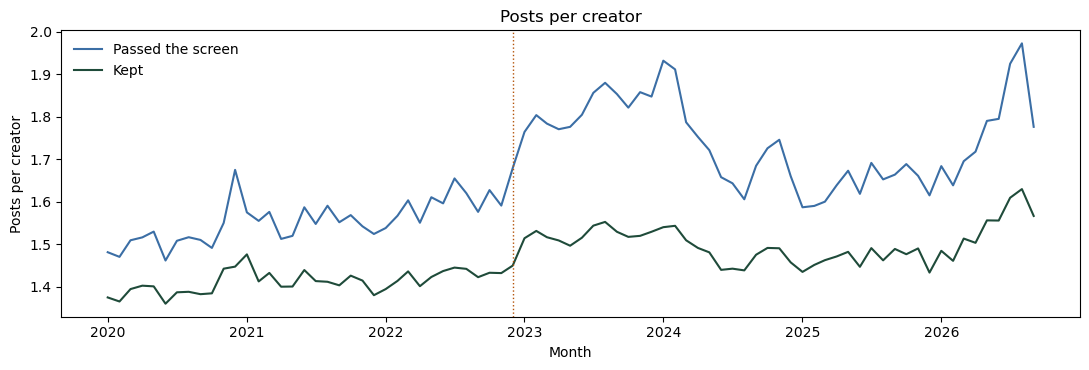

,period,"posts that passed, per creator","posts kept, per creator","creators with 4+ passing posts, %"
0,through Nov 2022,1.555,1.412,6.1
1,Dec 2022 through Aug 2026,1.738,1.498,9.0


In [3]:
volume["qual_per"] = volume["qualifying_posts"] / volume["sampled_creators"]
volume["sel_per"] = volume["selected_posts"] / volume["sampled_creators"]
# leave out the partial September 2026
full = volume[volume["year_month"] < "2026-09-01"].copy()
full["period"] = np.where(full["year_month"] < CUT, "pre", "post")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(volume["year_month"], volume["qual_per"], color="#3b6ea5", label="Passed the screen")
ax.plot(volume["year_month"], volume["sel_per"], color="#1f4b3a", label="Kept")
ax.axvline(CUT, color="#b45309", ls=":", lw=1)
ax.set_ylabel("Posts per creator")
ax.set_xlabel("Month")
ax.set_title("Posts per creator")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

def period_row(df, label):
    creators = df["sampled_creators"].sum()
    return {
        "period": label,
        "posts that passed, per creator": round(df["qualifying_posts"].sum() / creators, 3),
        "posts kept, per creator": round(df["selected_posts"].sum() / creators, 3),
        "creators with 4+ passing posts, %": round(100 * df["creators_with_4plus"].sum() / creators, 1),
    }

pd.DataFrame([
    period_row(full[full["period"] == "pre"], "through Nov 2022"),
    period_row(full[full["period"] == "post"], "Dec 2022 through Aug 2026"),
])


## Topics

There are eight keyword topics, and the target was 150 creators in each. Lifestyle (food, travel, home, leisure) is under 150 every month. The other misses get rarer after 2022, and a few are still there in 2026. Society, history and ideas is the big group, same as on Substack.


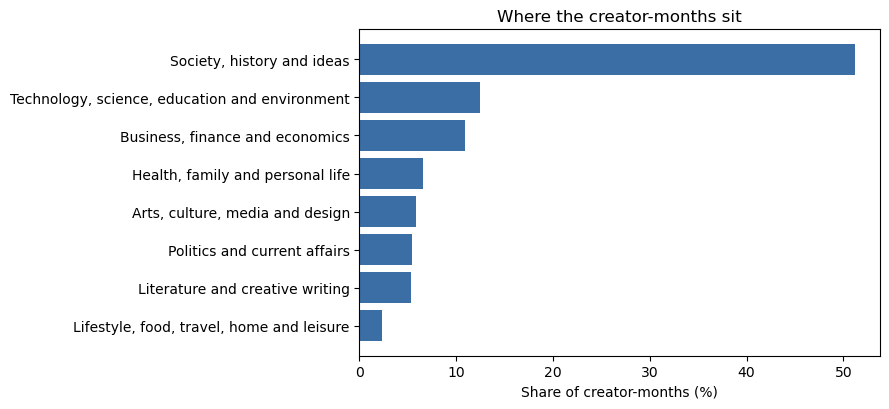

topic-months under 150: 255 of 648
year_month
2020-01    5
2020-02    5
2020-03    5
2020-04    3
2020-05    2
2020-06    3
2020-07    4
2020-08    5
Name: topics under 150, dtype: int64


In [4]:
topic = (
    coverage.groupby("topic_family", as_index=False)["sampled_creators"]
    .sum()
    .sort_values("sampled_creators")
)
topic["share_pct"] = 100 * topic["sampled_creators"] / topic["sampled_creators"].sum()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(topic["topic_family"], topic["share_pct"], color="#3b6ea5")
ax.set_xlabel("Share of creator-months (%)")
ax.set_title("Where the creator-months sit")
fig.tight_layout()
plt.show()

short = coverage.loc[
    coverage["topic_floor_shortfall"] > 0,
    ["year_month", "topic_family", "screened_candidate_creators", "sampled_creators", "topic_floor_shortfall"],
]
print("topic-months under 150:", len(short), "of", len(coverage))
print(short.groupby("year_month").size().rename("topics under 150").head(8))


## Do the same people come back?

Mostly no. Of 105,675 creators, 61,567 show up in a single month. The longest run in this draw is 10 months. 6,637 people show up at least once before December 2022 and at least once after.


creators 105,675
in one month only 61,567
longest run, months 10
median months 1
both sides of Dec 2022: 6,637
only before: 43,112
only after: 55,926


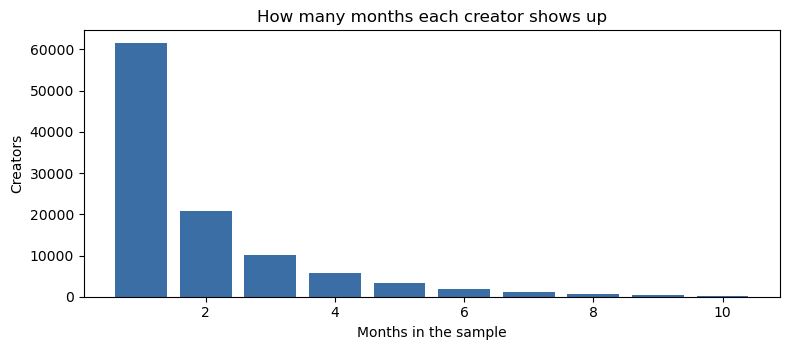

In [5]:
print("creators", f"{int(repeat['creators'].sum()):,}")
print("in one month only", f"{int(repeat.loc[repeat['months_in_sample']==1, 'creators'].sum()):,}")
print("longest run, months", int(repeat["months_in_sample"].max()))
# one row per creator, so the median is a person, not a bin
spells = repeat.loc[repeat.index.repeat(repeat["creators"]), "months_in_sample"]
print("median months", f"{spells.median():.0f}")
print("both sides of Dec 2022: 6,637")
print("only before: 43,112")
print("only after: 55,926")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(repeat["months_in_sample"], repeat["creators"], color="#3b6ea5", width=0.8)
ax.set_xlabel("Months in the sample")
ax.set_ylabel("Creators")
ax.set_title("How many months each creator shows up")
fig.tight_layout()
plt.show()


## How long the posts are

These are the posts that passed the screen: English, and at least 200 words. `primary_analysis_eligible` is false on all of them, and every saved body is marked `unverified_fullness`. Sampling is done. The analytic check is still open.

Posts get shorter from 2020 into 2023, then longer again through 2026. A single before/after average hides that turn. The slope below is a rough two-line fit on that curve. The monthly medians are the thing to read.


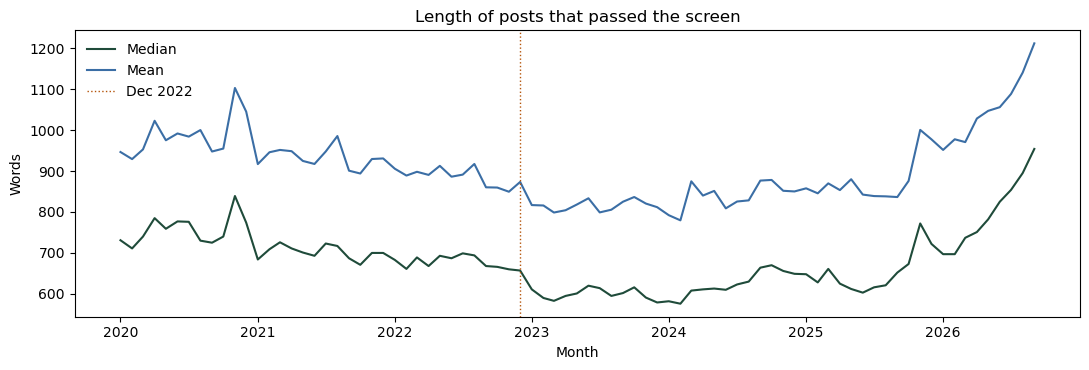

slope before Dec 2022 -2.89 words a month
slope after 4.38 words a month
level shift at the cut -104.2 words
Jan 2020 731 words
Nov 2022 660 words
Dec 2023 579 words
Aug 2026 895 words
posts marked ready for the main analysis 0


In [6]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(posts["year_month"], posts["median_words"], color="#1f4b3a", label="Median")
ax.plot(posts["year_month"], posts["mean_words"], color="#3b6ea5", label="Mean")
ax.axvline(CUT, color="#b45309", ls=":", lw=1, label="Dec 2022")
ax.set_ylabel("Words")
ax.set_xlabel("Month")
ax.set_title("Length of posts that passed the screen")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# drop partial Sep 2026. t = months since Jan 2020, so Dec 2022 is t = 35
fit = posts[posts["year_month"] < "2026-09-01"].copy()
fit["t"] = (fit["year_month"].dt.year - 2020) * 12 + (fit["year_month"].dt.month - 1)
cut_t = 35
fit["after"] = (fit["t"] >= cut_t).astype(float)
fit["t_after"] = np.maximum(fit["t"] - cut_t, 0.0)
X = np.column_stack([np.ones(len(fit)), fit["t"], fit["after"], fit["t_after"]])
y = fit["median_words"].to_numpy(float)
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
print("slope before Dec 2022", f"{beta[1]:.2f}", "words a month")
print("slope after", f"{beta[1] + beta[3]:.2f}", "words a month")
print("level shift at the cut", f"{beta[2]:.1f}", "words")

for label, ym in [
    ("Jan 2020", "2020-01-01"),
    ("Nov 2022", "2022-11-01"),
    ("Dec 2023", "2023-12-01"),
    ("Aug 2026", "2026-08-01"),
]:
    words = int(posts.loc[posts.year_month == ym, "median_words"].iloc[0])
    print(label, words, "words")
print("posts marked ready for the main analysis", int(posts["primary_analysis_eligible"].sum()))


## What we can say so far

The sample is large and the monthly draw is finished: about 2,500 creators in a full month, 201,520 creator-months, 294,671 posts kept, and 105,675 creators.

A few limits to keep in mind:

1. The analytic check is still open. Screened posts have `primary_analysis_eligible` set to false, and every saved body is `unverified_fullness`. A complete file can still be a cut-off article.
2. We only see what RSS returned. Some histories are still missing, and a creator id here is a source id.
3. Most creators appear once. The median is 1 month. 6,637 people show up on both sides of December 2022.
4. Topics come from keywords. The 150-creator floor is missed in 255 of 648 topic-months. Lifestyle misses it every month.
5. September 2026 stops on the 17th.

Length is the clear movement in the file. Median words go from 731 in January 2020 to 660 in November 2022, down to 579 in December 2023, then back up to 895 in August 2026. Posts were already getting shorter before ChatGPT, and they start getting longer well after.

We have not scored style yet, and we have not run the model-family check. The post text is in the zip, about 1.7 GB uncompressed.


## Topics month by month

Society, history and ideas stays the biggest share. Lifestyle stays under 150 creators every month, so the mix keeps sitting on the big topics.


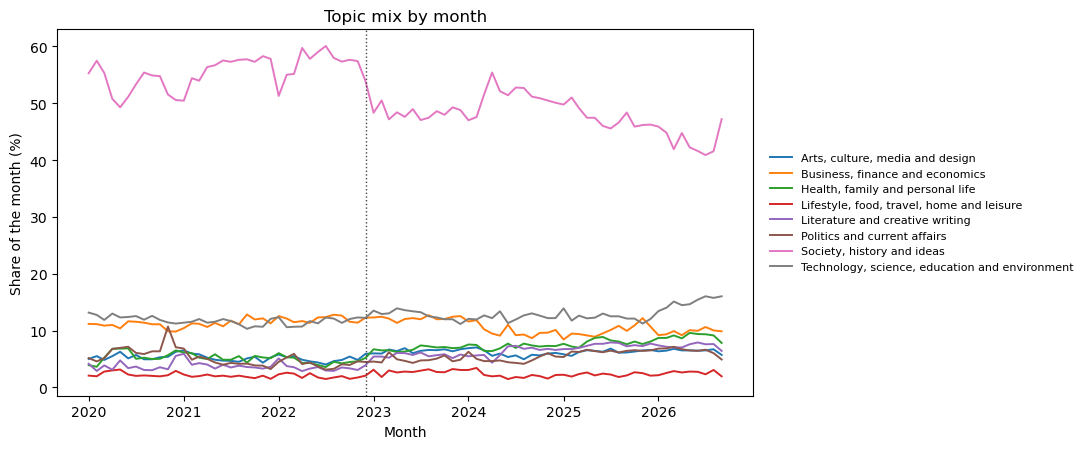

In [7]:
wide = coverage.pivot(index="year_month", columns="topic_family", values="sampled_creators")
wide.index = pd.to_datetime(wide.index + "-01")
share = wide.div(wide.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 4.6))
for name in share.columns:
    ax.plot(share.index, share[name], lw=1.4, label=name)
ax.axvline(CUT, color="#444444", ls=":", lw=1)
ax.set_ylabel("Share of the month (%)")
ax.set_xlabel("Month")
ax.set_title("Topic mix by month")
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()


## Writers on both sides of December 2022

6,637 creators have at least one month before the cut and one month after. Their posts average 986 words before and 1,007 after. The typical person in that group moved about 4 words. The middle half runs from about 290 words shorter to about 290 words longer.

The full monthly pool still drops, down to 579 words in December 2023. These repeat writers stay around the 700s through 2023, while the full pool falls into the high 500s. The dip is mostly new people coming into the sample.


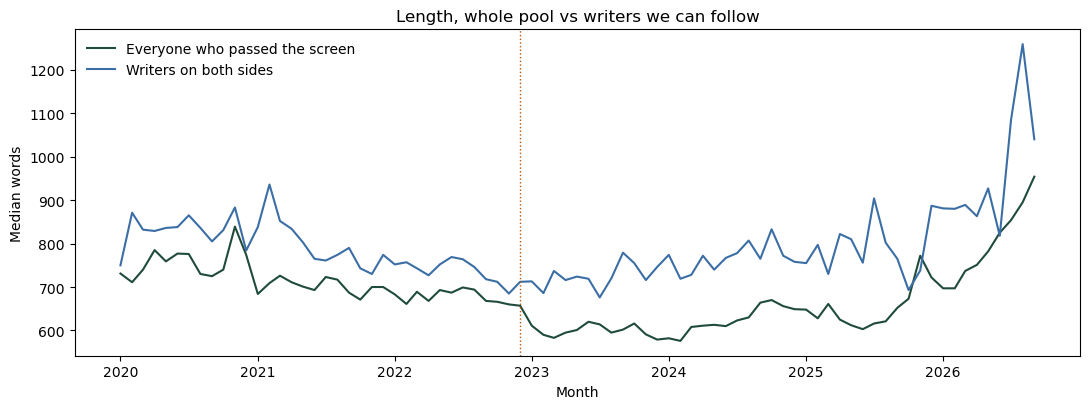

writers on both sides 6,637
their average before 986 words
their average after 1007 words
typical person's change 4 words
middle half -289 to 286 words


In [8]:
overlap = pd.read_csv(DATA / "overlap_length.csv", parse_dates=["year_month"])
paired = pd.read_csv(DATA / "overlap_paired.csv").iloc[0]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(posts["year_month"], posts["median_words"], color="#1f4b3a", label="Everyone who passed the screen")
ax.plot(overlap["year_month"], overlap["median_words"], color="#3b6ea5", label="Writers on both sides")
ax.axvline(CUT, color="#b45309", ls=":", lw=1)
ax.set_ylabel("Median words")
ax.set_xlabel("Month")
ax.set_title("Length, whole pool vs writers we can follow")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print("writers on both sides", f"{int(paired['creators']):,}")
print("their average before", f"{paired['mean_words_pre']:.0f}", "words")
print("their average after", f"{paired['mean_words_post']:.0f}", "words")
print("typical person's change", f"{paired['median_creator_diff']:.0f}", "words")
print(
    "middle half",
    f"{paired['p25_creator_diff']:.0f}",
    "to",
    f"{paired['p75_creator_diff']:.0f}",
    "words",
)


## Next to Substack

Same years, same cap of 2,500, same topic list. Substack keeps a shrinking share of a pool that grows fast, and the same writers stay for years. Medium's screened pool grows more slowly. Creators mostly appear once. The length dip in Medium's monthly pool is small among the writers we can follow.


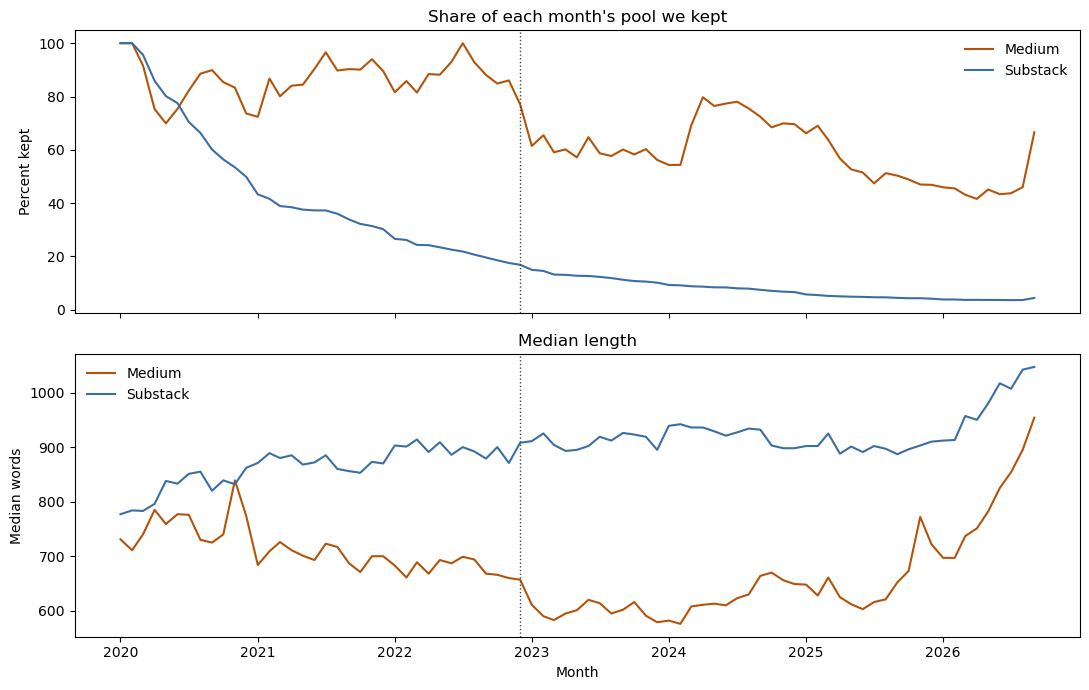

,platform,creators,median months,on both sides,"words, Jan 2020","words, Nov 2022","words, Aug 2026","avg change, words"
0,Medium,105675,1,6637,731,660,895,21.6
1,Substack,24744,5,3793,777,871,1042,90.2


In [9]:
sub_cov = pd.read_csv(DATA.parent / "substack_eda" / "monthly_coverage.csv")
sub_posts = pd.read_csv(DATA.parent / "substack_eda" / "post_length_engagement.csv", parse_dates=["year_month"])
sub_repeat = pd.read_csv(DATA.parent / "substack_eda" / "creator_repeat.csv")
sub_paired = pd.read_csv(DATA.parent / "substack_eda" / "overlap_paired.csv").iloc[0]

sub_month = sub_cov.groupby("year_month", as_index=False).agg(
    eligible=("eligible_candidate_creators", "sum"),
    sampled=("sampled_creators", "sum"),
)
sub_month["year_month"] = pd.to_datetime(sub_month["year_month"] + "-01")
sub_month["kept_pct"] = 100 * sub_month["sampled"] / sub_month["eligible"]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(month["year_month"], month["kept_pct"], color="#b45309", label="Medium")
axes[0].plot(sub_month["year_month"], sub_month["kept_pct"], color="#3b6ea5", label="Substack")
axes[0].axvline(CUT, color="#444444", ls=":", lw=1)
axes[0].set_ylabel("Percent kept")
axes[0].set_title("Share of each month's pool we kept")
axes[0].legend(frameon=False)
axes[1].plot(posts["year_month"], posts["median_words"], color="#b45309", label="Medium")
axes[1].plot(sub_posts["year_month"], sub_posts["median_words"], color="#3b6ea5", label="Substack")
axes[1].axvline(CUT, color="#444444", ls=":", lw=1)
axes[1].set_ylabel("Median words")
axes[1].set_xlabel("Month")
axes[1].set_title("Median length")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

def median_spell(rep):
    spells = rep.loc[rep.index.repeat(rep["creators"]), "months_in_sample"]
    return int(spells.median()), int(rep["creators"].sum())

med_months, med_n = median_spell(repeat)
sub_months, sub_n = median_spell(sub_repeat)

def word_at(frame, ym):
    return int(frame.loc[frame.year_month == ym, "median_words"].iloc[0])

compare = pd.DataFrame([
    {
        "platform": "Medium",
        "creators": med_n,
        "median months": med_months,
        "on both sides": int(paired["creators"]),
        "words, Jan 2020": word_at(posts, "2020-01-01"),
        "words, Nov 2022": word_at(posts, "2022-11-01"),
        "words, Aug 2026": word_at(posts, "2026-08-01"),
        "avg change, words": round(paired["mean_words_post"] - paired["mean_words_pre"], 1),
    },
    {
        "platform": "Substack",
        "creators": sub_n,
        "median months": sub_months,
        "on both sides": int(sub_paired["creators"]),
        "words, Jan 2020": word_at(sub_posts, "2020-01-01"),
        "words, Nov 2022": word_at(sub_posts, "2022-11-01"),
        "words, Aug 2026": word_at(sub_posts, "2026-08-01"),
        "avg change, words": round(sub_paired["mean_words_post"] - sub_paired["mean_words_pre"], 1),
    },
])
compare


## Where that leaves us

On Medium, the monthly posts get shorter into 2023 and longer again by 2026. The 6,637 writers on both sides of December 2022 move about 22 words on average, and the typical one moves about 4.

On Substack, the posts we kept get longer across the whole window. The writers on both sides get longer too, about 90 words on average. These are different sites, with different frames, and Medium's article bodies are still marked unverified.

The shard snapshots are the crawl behind this zip. This notebook uses the sampled zip.
